# Light Deflection versus Black-Hole Spin

The deflection angle is computed for every combination of spin $a$ and cosmological constant $\Lambda$
(same method as `Lambda_Deflection.ipynb`); for each $\Lambda$ the results are then fitted with the model
$\delta(a) = A\,e^{-B a} + C$. All data are taken directly from the simulation.
See `docs/METHODOLOGY.md` for the full methodology.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from kerr_ds import run_spin_sweep, fit_curve, exponential_decay, plot_spin_fit

## Parameters

In [2]:
# Physical parameters
M = 1.0
spins = [0.0, 0.2, 0.4, 0.6, 0.8, 0.99]
lambdas = [0.0, 1e-8, 5e-8, 1e-7, 5e-7, 1e-6, 5e-6]

# Initial position of the photon
r0 = 500.0
theta0 = np.pi / 2
phi0 = 0.0

# Photon energy and impact parameter (L = b E)
E = 1.0
b = 7
L_ang = b * E

# Integration parameters
dtau = 0.05
max_steps = 30000

## Simulation

All combinations (6 spins × 7 values of $\Lambda$ = 42 trajectories) run in parallel in a single process pool
(about 2.5 minutes on a 4-core CPU). The horizon radius used for the capture condition is computed per spin.

In [3]:
results = run_spin_sweep(M, spins, lambdas, r0, theta0, phi0, E, L_ang,
                         dtau=dtau, max_steps=max_steps)

a          | Lambda     | Deflection (deg)     | Status
-------------------------------------------------------


0.0        | 0.0        | 63.0126              | Steps: 20167


0.0        | 1e-08      | 63.0126              | Steps: 20167


0.0        | 5e-08      | 63.0127              | Steps: 20167


0.0        | 1e-07      | 63.0127              | Steps: 20167


...

0.99       | 5e-08      | 43.9159              | Steps: 20140


0.99       | 1e-07      | 43.9169              | Steps: 20140


0.99       | 5e-07      | 43.9252              | Steps: 20140


0.99       | 1e-06      | 43.9359              | Steps: 20140


0.99       | 5e-06      | 44.0355              | Steps: 20140


## Deflection table (degrees)

In [4]:
# deflections[Lambda] = deflection for each spin (in the order of `spins`)
deflections = {lmd: np.array([results[a, lmd].deflection_deg for a in spins]) for lmd in lambdas}

print(f"{'Lambda':<10}" + "".join(f"{f'a = {a}':>12}" for a in spins))
for lmd, y in deflections.items():
    print(f"{lmd:<10}" + "".join(f"{v:>12.4f}" for v in y))

Lambda         a = 0.0     a = 0.2     a = 0.4     a = 0.6     a = 0.8    a = 0.99
0.0            63.0126     57.6105     53.2305     49.5803     46.4747     43.9149
1e-08          63.0126     57.6106     53.2306     49.5804     46.4748     43.9151
5e-08          63.0127     57.6108     53.2309     49.5810     46.4755     43.9159
1e-07          63.0127     57.6110     53.2314     49.5816     46.4763     43.9169
5e-07          63.0132     57.6130     53.2350     49.5868     46.4831     43.9252
1e-06          63.0138     57.6156     53.2396     49.5933     46.4918     43.9359
5e-06          63.0186     57.6393     53.2823     49.6553     46.5730     44.0355


## Exponential fits

For each $\Lambda$: $\delta(a) = A\,e^{-B a} + C$ (`scipy.optimize.curve_fit`), with
$R^2 = 1 - SS_\text{res}/SS_\text{tot}$.

In [5]:
fits = {}
for lmd, y in deflections.items():
    fits[lmd] = fit_curve(exponential_decay, spins, y, p0=[300, 5, 70], maxfev=10000)
    (A, B, C), r2 = fits[lmd]
    print(f"Λ = {lmd:<8g}: y = {A:.4f} * e^(-{B:.4f} * a) + {C:.4f}   (R² = {r2:.6f})")

Λ = 0       : y = 32.3843 * e^(-0.8940 * a) + 30.5940   (R² = 0.999955)
Λ = 1e-08   : y = 32.3838 * e^(-0.8940 * a) + 30.5945   (R² = 0.999955)
Λ = 5e-08   : y = 32.3816 * e^(-0.8940 * a) + 30.5968   (R² = 0.999955)
Λ = 1e-07   : y = 32.3789 * e^(-0.8941 * a) + 30.5995   (R² = 0.999955)
Λ = 5e-07   : y = 32.3568 * e^(-0.8945 * a) + 30.6221   (R² = 0.999955)
Λ = 1e-06   : y = 32.3283 * e^(-0.8950 * a) + 30.6512   (R² = 0.999955)
Λ = 5e-06   : y = 32.0624 * e^(-0.8997 * a) + 30.9222   (R² = 0.999956)


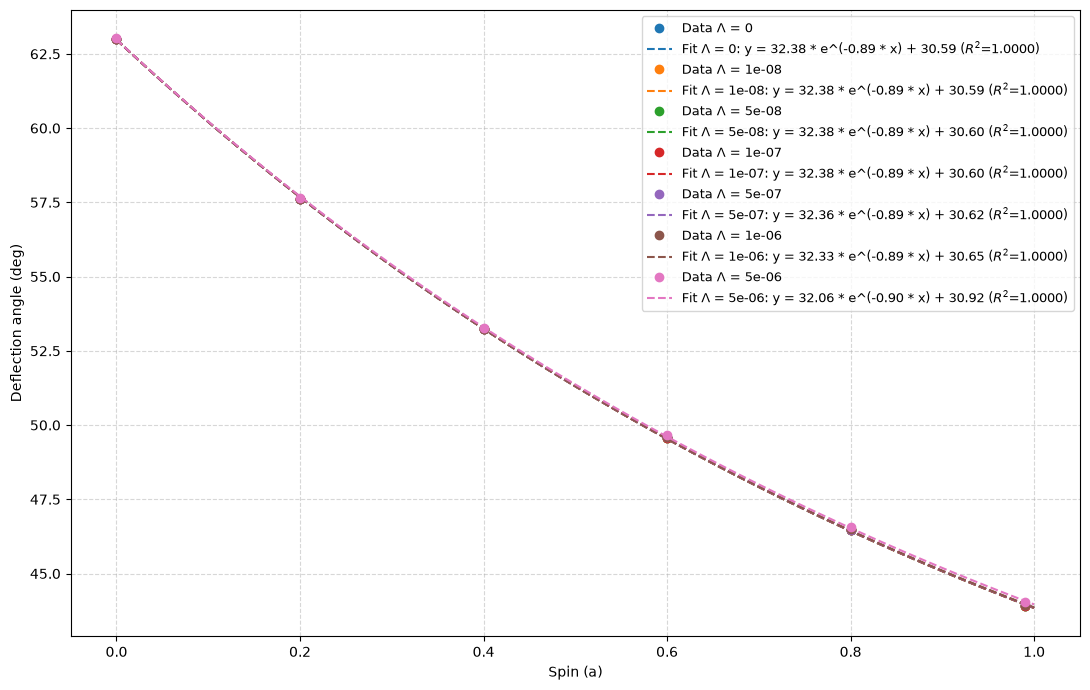

In [6]:
plot_spin_fit(spins, deflections, fits)
plt.show()